<a href="https://colab.research.google.com/github/ricardoasf/Previsao-Series-Temporais/blob/main/RegressaoRidge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
#Definição das bibliotecas usadas
import pandas as pd #álgebra linear
import numpy as np #processamento de dados

import matplotlib as mpl
import matplotlib.pyplot as plt #visualização de dados
import seaborn as sns #visualização de dados

############### PARAMETRIZAÇÃO PARA EXECUÇÃO #############
# 1 - para Jupyter/Outras IDEs;
# 2 - para GoogleColab
carga_dados = 2
##########################################################

if carga_dados == 1:
    #Carrega Série Temporal a partir de Planilha de Dados no formato de DataFrame
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk()
    root.withdraw()
    caminho_arquivo = filedialog.askopenfilename()
    df = pd.read_csv(caminho_arquivo)
else:
    #Carrega Dados para GoogleColab
    import io
    from google.colab import files
    uploaded = files.upload()
    #Obtém o nome do arquivo que foi feito upload
    nome_arquivo = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[nome_arquivo]))

df

Saving Dataset2.csv to Dataset2 (1).csv


,Data,Demanda,Dolar,Eolica,Balanco,Preco
0,7/1/2009 0:00,12336,1.1572,37,-1310,14.25
1,7/1/2009 1:00,11973,1.1572,13,-1561,8.43
2,7/1/2009 2:00,11731,1.1572,15,-1890,1.88
3,7/1/2009 3:00,11553,1.1572,20,-1764,11.00
4,7/1/2009 4:00,11588,1.1572,26,-1962,4.21
...,...,...,...,...,...,...
1003,8/11/2009 19:00,19179,1.0843,131,-1117,33.12
1004,8/11/2009 20:00,19192,1.0843,83,-898,38.14
1005,8/11/2009 21:00,17504,1.0843,74,-1080,34.04
1006,8/11/2009 22:00,15912,1.0843,67,-995,20.80


In [7]:
#Transforma a Coluna Data em DateTime
df['DateTime'] = pd.to_datetime(df['Data'])

#Torna a Coluna DateTime o índice do DataFrame
df = df.set_index(df['DateTime'])

#Clona o DataFrame e Normaliza as Colunas pela primeira amostra
df_clone = df[:]
df_clone['Demanda'] = df['Demanda'] / df['Demanda'].iloc[0]
df_clone['Dolar'] = df['Dolar'] / df['Dolar'].iloc[0]
df_clone['Eolica'] = df['Eolica'] / df['Eolica'].iloc[0]
df_clone['Balanco'] = df['Balanco'] / df['Balanco'].iloc[0]
df_clone['Preco'] = df['Preco'] / df['Preco'].iloc[0]

#Copia apenas as colunas de interesse do Clone para o novo DataFrame
df_norm = df_clone[['Demanda','Dolar', 'Eolica', 'Balanco', 'Preco']]
df_norm

,Demanda,Dolar,Eolica,Balanco,Preco
DateTime,,,,,
2009-07-01 00:00:00,1.000000,1.000000,1.000000,1.000000,1.000000
2009-07-01 01:00:00,0.970574,1.000000,0.351351,1.191603,0.591579
2009-07-01 02:00:00,0.950957,1.000000,0.405405,1.442748,0.131930
2009-07-01 03:00:00,0.936527,1.000000,0.540541,1.346565,0.771930
2009-07-01 04:00:00,0.939364,1.000000,0.702703,1.497710,0.295439
...,...,...,...,...,...
2009-08-11 19:00:00,1.554718,0.937003,3.540541,0.852672,2.324211
2009-08-11 20:00:00,1.555772,0.937003,2.243243,0.685496,2.676491
2009-08-11 21:00:00,1.418936,0.937003,2.000000,0.824427,2.388772


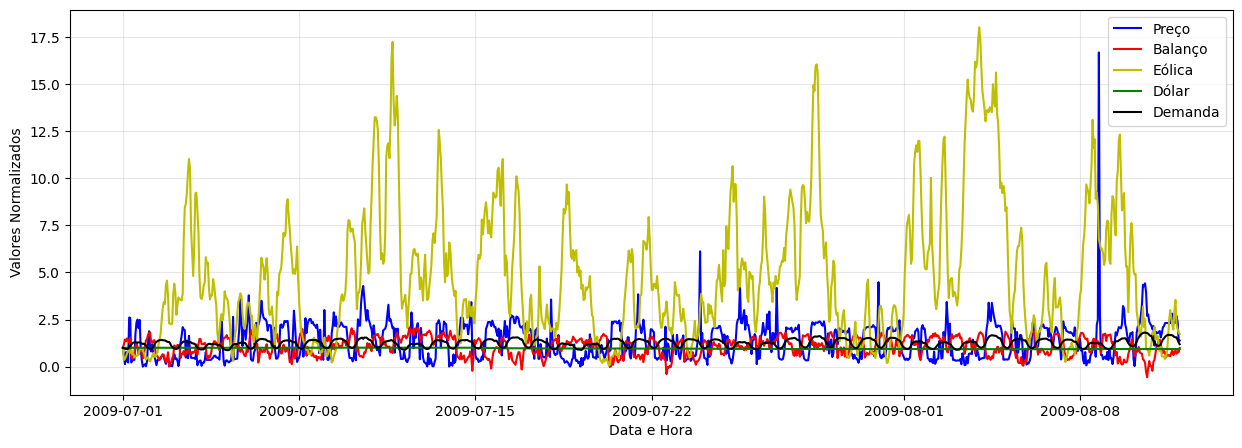

In [9]:
#Análise Gráfica dos Dados
plt.figure(figsize=(15, 5))

plt.plot(df_norm['Preco'], 'b', label='Preço')
plt.plot(df_norm['Balanco'], 'r', label='Balanço')
plt.plot(df_norm['Eolica'], 'y', label='Eólica')
plt.plot(df_norm['Dolar'], 'g', label='Dólar')
plt.plot(df_norm['Demanda'], 'k', label='Demanda')

plt.xlabel('Data e Hora')
plt.ylabel('Valores Normalizados')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
#Clona o DataFrame normalizado para um novo
df_lagged = df_norm[:]

#Determina os atrasos
lags = (1, 7)

#Gera o DataFrame com as Colunas de Atraso
df_lagged = df_norm.assign(**{f'{col}_t-{lag}': df_norm[col].shift(lag) for lag in lags for col in df_norm})

#Exclui valor NaN
df_proc = df_lagged.dropna()

#Mostra dados mais recentes
df_proc

,Demanda,Dolar,Eolica,Balanco,Preco,Demanda_t-1,Dolar_t-1,Eolica_t-1,Balanco_t-1,Preco_t-1,Demanda_t-7,Dolar_t-7,Eolica_t-7,Balanco_t-7,Preco_t-7
DateTime,,,,,,,,,,,,,,,
2009-07-01 07:00:00,1.107166,1.000000,0.729730,1.525191,2.585965,1.043126,1.000000,0.810811,1.261832,2.607719,1.000000,1.000000,1.000000,1.000000,1.000000
2009-07-01 08:00:00,1.170639,1.000000,0.891892,0.553435,0.219649,1.107166,1.000000,0.729730,1.525191,2.585965,0.970574,1.000000,0.351351,1.191603,0.591579
2009-07-01 09:00:00,1.235976,1.000000,0.648649,0.420611,0.315789,1.170639,1.000000,0.891892,0.553435,0.219649,0.950957,1.000000,0.405405,1.442748,0.131930
2009-07-01 10:00:00,1.273914,1.000000,0.675676,0.661832,0.348772,1.235976,1.000000,0.648649,0.420611,0.315789,0.936527,1.000000,0.540541,1.346565,0.771930
2009-07-01 11:00:00,1.290613,1.000000,0.486486,0.549618,0.360000,1.273914,1.000000,0.675676,0.661832,0.348772,0.939364,1.000000,0.702703,1.497710,0.295439
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2009-08-11 19:00:00,1.554718,0.937003,3.540541,0.852672,2.324211,1.567283,0.937003,3.000000,0.767176,2.353684,1.692445,0.937003,1.594595,0.590840,2.307368
2009-08-11 20:00:00,1.555772,0.937003,2.243243,0.685496,2.676491,1.554718,0.937003,3.540541,0.852672,2.324211,1.685392,0.937003,2.513514,0.597710,2.310877
2009-08-11 21:00:00,1.418936,0.937003,2.000000,0.824427,2.388772,1.555772,0.937003,2.243243,0.685496,2.676491,1.670315,0.937003,3.000000,0.552672,2.312281


In [12]:
#Define as colunas que serão variáveis de entrada - explicativas
features = df_proc.columns[[5, 10]]
features

Index(['Demanda_t-1', 'Demanda_t-7'], dtype='object')

In [13]:
#Define as coluna que será variável de saída - interesse
target = df_proc.columns[[0]]
target

Index(['Demanda'], dtype='object')

In [14]:
#Separação de Dados para Ajuste e Validação dos Modelos
df_t_ajuste = df_proc['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao = df_proc['2009-08-01 00:00:00':].index.values
df_dados_ajuste = df_proc['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao = df_proc['2009-08-01 00:00:00':]

X_ajuste = df_dados_ajuste[features].values
Y_ajuste = df_dados_ajuste[target].values
X_validacao = df_dados_validacao[features].values
Y_validacao = df_dados_validacao[target].values

In [40]:
# Parametrização de Modelo de Regressão Ridge
from sklearn.linear_model import Ridge, RidgeCV

#alpha deve ser positivo
#Se alpha = 0, então Ridge = Linear
modelo_Ridge = Ridge(alpha=3).fit(X_ajuste, Y_ajuste)

In [41]:
df_previsto_Ridge = modelo_Ridge.predict(X_validacao)
df_previsto_Ridge_denorm = df_previsto_Ridge * df['Demanda'].iloc[0]

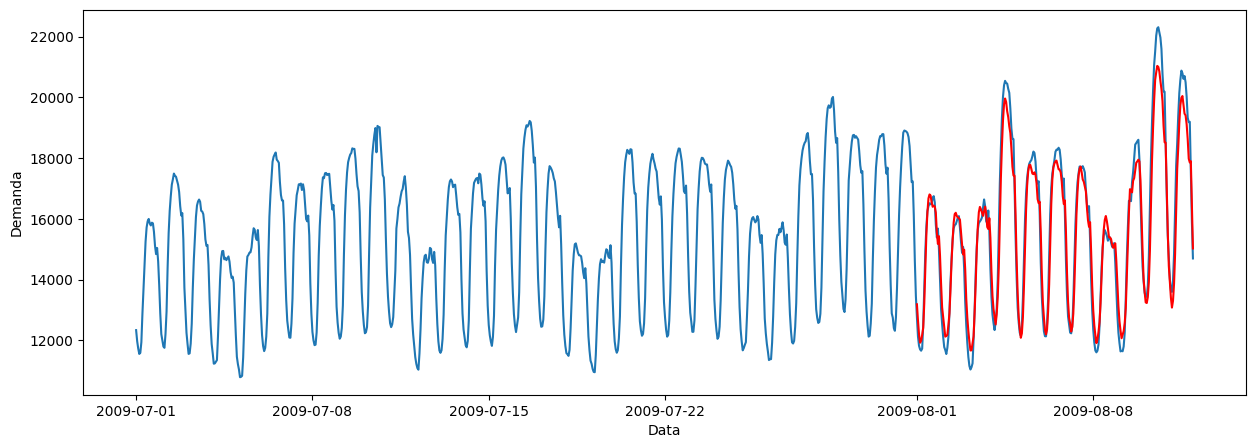

In [42]:
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Demanda'])
plt.plot(df_dados_validacao.index, df_previsto_Ridge_denorm, 'r')
plt.ylabel('Demanda')
plt.xlabel('Data')
plt.show()

In [43]:
r_sq = modelo_Ridge.score(X_validacao, Y_validacao)
print(f"R2: {r_sq}")
print(f"Interceptação: {modelo_Ridge.intercept_}")
print(f"Inclinação: {modelo_Ridge.coef_}")

R2: 0.9468111714744416
Interceptação: [0.33605827]
Inclinação: [ 0.88003503 -0.15244009]
